In [4]:
!pip3 install pandas
!pip3 install openpyxl
!pip3 install tqdm
!pip3 install pathlib
!pip3 install matplotlib
!pip3 install seaborn
!pip3 install statsmodels
!pip3 install geopandas 
!pip3 install contextily

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user insta

In [5]:
import pandas as pd
from pathlib import Path
from tqdm import tqdm


def fill_missing_bedrock(data: pd.DataFrame) -> pd.DataFrame:
    id_col = 'WI_UNIQUE_WELL_NO'
    bedrock_col = 'FIRST_BEDROCK_FT'
    previous_col = 'PREVIOUS_WELL_NO'
    replacement_col = 'REPLACEMENT_WELL_NO'

    missing_columns = {id_col, bedrock_col, previous_col, replacement_col} - set(data.columns)
    if missing_columns:
        raise KeyError(f"Missing expected column(s): {sorted(missing_columns)}")

    bedrock_lookup = (
        data
        .dropna(subset=[id_col])
        .drop_duplicates(subset=[id_col], keep='first')
        .set_index(id_col)[bedrock_col]
    )

    previous_bedrock = data[previous_col].map(bedrock_lookup)
    replacement_bedrock = data[replacement_col].map(bedrock_lookup)

    data[bedrock_col] = data[bedrock_col].fillna(previous_bedrock).fillna(replacement_bedrock)
    return data


def main():
    input_path = Path(
        "/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/All WI Wells Shortened for GitHub.xlsx"
    )

    output_path = Path(
        "/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/"
        "University of Wisconsin Water Science Lab Docs/Savannah/"
        "Populated_All_Wisconsin_Wells.xlsx"
    )

    try:
        with tqdm(total=4, desc="Overall progress", unit="step") as progress:
            data = pd.read_excel(input_path)
            progress.update(1)

            data = data.sort_values('WI_UNIQUE_WELL_NO')
            progress.update(1)

            data = fill_missing_bedrock(data)
            progress.update(1)

            data.to_excel(output_path, index=False)
            progress.update(1)

        print(f"Updated file saved to: {output_path}")

    except FileNotFoundError:
        print(f"The file does not exist: {input_path}")
    except KeyError as e:
        print(f"Missing expected column: {e}")
    except Exception as e:
        print(f"An error occurred: {e}")


if __name__ == "__main__":
    main()


Overall progress: 100%|██████████| 4/4 [00:59<00:00, 15.00s/step]

Updated file saved to: /Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/University of Wisconsin Water Science Lab Docs/Savannah/Populated_All_Wisconsin_Wells.xlsx


In [6]:
from pathlib import Path
from typing import List, Optional, Union

import pandas as pd
from tqdm import tqdm


class ExcelDataCleaner:
    def __init__(self, file_path: Union[str, Path], sheet_name: str, usecols: Optional[Union[List[str], str]] = None):
        self.file_path = Path(file_path)
        self.sheet_name = sheet_name
        self.usecols = usecols
        self.df = self._load_excel()

    def _load_excel(self) -> pd.DataFrame:
        if not self.file_path.exists():
            raise FileNotFoundError(f"Excel file not found: {self.file_path}")
        return pd.read_excel(
            self.file_path,
            sheet_name=self.sheet_name,
            usecols=self.usecols,
            engine="openpyxl",
        )

    def _validate_columns(self, required_columns: List[str]) -> None:
        missing = [col for col in required_columns if col not in self.df.columns]
        if missing:
            raise KeyError(f"Missing required columns: {missing}")

    def describe_column(self, column_name: str) -> pd.Series:
        self._validate_columns([column_name])
        return self.df[column_name]

    def filter_negative_and_missing(self, value_column: str, well_number_column: str) -> pd.DataFrame:
        self._validate_columns([value_column, well_number_column])
        mask = self.df[value_column].ge(0) & self.df[well_number_column].notna()
        self.df = self.df.loc[mask].reset_index(drop=True)
        return self.df

    def get_unique_well_numbers(self, well_number_column: str):
        self._validate_columns([well_number_column])
        return self.df[well_number_column].dropna().unique()

    def save(self, output_path: Union[str, Path]) -> None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        self.df.to_excel(output_path, index=False)


def main() -> None:
    file_path = Path("/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/Ra Contaminants in WI Public Water Supplies for GitHub.xlsx")
    sheet_name = "All Ra Wells"
    value_column = "Measured Amount"
    well_number_column = "WI_UNIQUE_WELL_NO"
    output_file_path = Path("filtered_radium_data_dnr.xlsx")

    with tqdm(total=3, desc="Processing Excel file", unit="step") as progress:
        cleaner = ExcelDataCleaner(
            file_path=file_path,
            sheet_name=sheet_name,
            usecols=None,
        )
        progress.update(1)

        original_row_count = len(cleaner.df)
        original_unique_wells = cleaner.df[well_number_column].nunique(dropna=True)

        print(f"Loaded {original_row_count} rows from '{sheet_name}'")
        print(f"Original unique wells: {original_unique_wells}")

        cleaner.filter_negative_and_missing(value_column, well_number_column)
        progress.update(1)
        cleaned_row_count = len(cleaner.df)
        cleaned_unique_wells = len(cleaner.get_unique_well_numbers(well_number_column))

        print(f"Rows after filtering negatives and missing well numbers: {cleaned_row_count}")
        print(f"Unique wells after filtering: {cleaned_unique_wells}")

        cleaner.save(output_file_path)
        progress.update(1)
        print(f"Saved filtered data to: {output_file_path}")


if __name__ == "__main__":
    main()


Processing Excel file:  33%|███▎      | 1/3 [00:00<00:00,  4.59step/s]

Loaded 1662 rows from 'All Ra Wells'
Original unique wells: 549
Rows after filtering negatives and missing well numbers: 1564
Unique wells after filtering: 548


Processing Excel file: 100%|██████████| 3/3 [00:00<00:00,  3.87step/s]

Saved filtered data to: filtered_radium_data_dnr.xlsx


In [7]:
from pathlib import Path

import pandas as pd
from tqdm import tqdm


def read_excel_sheet(file_path: Path, sheet_name: str) -> pd.DataFrame:
    if not file_path.exists():
        raise FileNotFoundError(f"Excel file not found: {file_path}")
    try:
        return pd.read_excel(file_path, sheet_name=sheet_name, engine="openpyxl")
    except ValueError as exc:
        raise ValueError(f"Sheet '{sheet_name}' not found in {file_path}") from exc


def merge_excel_files(
    file1: Path,
    file2: Path,
    sheet1: str,
    sheet2: str,
    output_file: Path,
    on: str = "WI_UNIQUE_WELL_NO",
    how: str = "inner",
) -> pd.DataFrame:
    with tqdm(total=4, desc="Merging Excel files", unit="step") as progress:
        df1 = read_excel_sheet(file1, sheet1)
        progress.update(1)

        df2 = read_excel_sheet(file2, sheet2)
        progress.update(1)

        merged_df = pd.merge(df1, df2, on=on, how=how)
        progress.update(1)

        output_file.parent.mkdir(parents=True, exist_ok=True)
        merged_df.to_excel(output_file, index=False)
        progress.update(1)

    return merged_df


def main() -> None:
    file1 = Path(
        "/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/University of Wisconsin Water Science Lab Docs/Savannah/Populated_All_Wisconsin_Wells.xlsx"
    )
    file2 = Path(
        "/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/filtered_radium_data_dnr.xlsx"
    )
    sheet1 = "Sheet1"
    sheet2 = "Sheet1"
    output_file = Path(
        "/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/merged_all_wells_ra_dnr.xlsx"
    )

    merged_df = merge_excel_files(file1, file2, sheet1, sheet2, output_file)
    print(f"Merged data saved to {output_file} ({len(merged_df)} rows)")


if __name__ == "__main__":
    main()


Merging Excel files: 100%|██████████| 4/4 [00:23<00:00,  5.77s/step]

Merged data saved to /Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/merged_all_wells_ra_dnr.xlsx (1564 rows)


In [8]:
from pathlib import Path

import pandas as pd
from tqdm import tqdm

def first_bedrock_filter(
    file_name: str,
    sheet_name: str,
    column_name: str,
    output_file_name: str,
) -> None:
    input_path = Path(file_name)
    output_path = Path(output_file_name)

    if not input_path.exists():
        raise FileNotFoundError(f"The file does not exist: {input_path}")

    df = pd.read_excel(input_path, sheet_name=sheet_name)

    if column_name not in df.columns:
        raise KeyError(f"Column not found: {column_name}")

    with tqdm(total=3, desc="Filtering wells", unit="step") as progress:
        progress.update(1)

        filtered_df = df.dropna(subset=[column_name]).reset_index(drop=True)
        progress.update(1)

        output_path.parent.mkdir(parents=True, exist_ok=True)
        filtered_df.to_excel(output_path, index=False)
        progress.update(1)

    print(f"Filtered {len(df) - len(filtered_df)} rows with missing '{column_name}'.")
    print(f"Modified output saved to '{output_path}'.")

def main():
    # Example usage
    file_name = '/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/merged_all_wells_ra_dnr.xlsx'
    sheet_name = 'Sheet1'
    column_name = 'FIRST_BEDROCK_FT'
    output_file_name = '/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/filtered_sand_and_gravel_wells_dnr.xlsx' #file name

    first_bedrock_filter(file_name, sheet_name, column_name, output_file_name)

if __name__ == "__main__":
    main()


Filtering wells: 100%|██████████| 3/3 [00:00<00:00,  6.04step/s]

Filtered 186 rows with missing 'FIRST_BEDROCK_FT'.
Modified output saved to '/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/filtered_sand_and_gravel_wells_dnr.xlsx'.


In [9]:
from pathlib import Path
from typing import Optional

import pandas as pd
from tqdm import tqdm


def read_excel_file(file_path: Path, sheet_name: Optional[str] = None) -> pd.DataFrame:
    if not file_path.exists():
        raise FileNotFoundError(f"The file does not exist: {file_path}")

    df = pd.read_excel(file_path, sheet_name=sheet_name, engine="openpyxl", parse_dates=["Sample Date"])

    # Make datetime columns timezone-naive for consistency
    for col in df.select_dtypes(include=["datetimetz"]):
        df[col] = df[col].dt.tz_localize(None)

    return df


def wells_sampled(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["Sample Date"] = pd.to_datetime(df["Sample Date"], errors="coerce")
    df["Year"] = df["Sample Date"].dt.year

    # Keep only the highest measured amount per well-year
    idx = df.groupby(["WI_UNIQUE_WELL_NO", "Year"])["Measured Amount"].idxmax()
    result = df.loc[idx].copy()
    result["Count"] = df.groupby(["WI_UNIQUE_WELL_NO", "Year"])["Measured Amount"].transform("count").loc[idx].astype(int)
    result.reset_index(drop=True, inplace=True)
    return result


def main():
    file_path = "/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/filtered_sand_and_gravel_wells_dnr.xlsx"
    
    sheet_name = "Sheet1"
    

    input_path = Path(file_path)
    output_path = Path.cwd() / "filtered_annual_maximum_radium.xlsx"

    with tqdm(total=3, desc="Annual max radium", unit="step") as progress:
        df = read_excel_file(input_path, sheet_name=sheet_name)
        progress.update(1)

        wells_data = wells_sampled(df)
        progress.update(1)

        wells_data.to_excel(output_path, index=False)
        progress.update(1)

    print(f"Updated wells in dataset: {len(wells_data)} rows")
    print(f"Saved annual maximum radium data to '{output_path}'.")


if __name__ == "__main__":
    main()


Annual max radium: 100%|██████████| 3/3 [00:00<00:00,  3.33step/s]

Updated wells in dataset: 1218 rows
Saved annual maximum radium data to '/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/filtered_annual_maximum_radium.xlsx'.


In [10]:
#!/usr/bin/env python3
from __future__ import annotations

import argparse
from pathlib import Path
from typing import Union

import matplotlib.pyplot as plt
import pandas as pd


MCL_DEFAULT = 5.0

# Works in both normal Python scripts and Jupyter notebooks
try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()

DEFAULT_INPUT_FILE = BASE_DIR / "filtered_annual_maximum_radium.xlsx"
DEFAULT_OUTPUT_DIR = BASE_DIR / "analysis_outputs"


In [11]:
#!/usr/bin/env python3
from __future__ import annotations

import argparse
from pathlib import Path
from typing import Union

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf


MCL_DEFAULT = 5.0

# Default paths for the Excel file uploaded in this ChatGPT session.
# Change these if you move the notebook or Excel file to another folder.
DEFAULT_INPUT_FILE = Path.cwd() / "filtered_annual_maximum_radium.xlsx"
DEFAULT_OUTPUT_DIR = Path.cwd() / "analysis_outputs"


def clean_column_names(data: pd.DataFrame) -> pd.DataFrame:
    """Convert column names to easier snake_case names."""
    renamed = {
        col: (
            col.strip()
            .replace(" ", "_")
            .replace("(", "")
            .replace(")", "")
            .replace("/", "_per_")
            .replace("-", "_")
            .lower()
        )
        for col in data.columns
    }
    return data.rename(columns=renamed)


def load_data(input_path: Path, sheet_name: Union[str, int] = 0) -> pd.DataFrame:
    """Load and clean the radium Excel dataset."""
    data = pd.read_excel(input_path, sheet_name=sheet_name)
    data = clean_column_names(data)

    required_columns = [
        "wi_unique_well_no",
        "measured_amount",
        "sample_date",
        "year",
        "county",
        "region",
        "first_bedrock_ft",
        "maximum_contaminant_limit_mcl",
    ]

    missing = [col for col in required_columns if col not in data.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    data["sample_date"] = pd.to_datetime(data["sample_date"], errors="coerce")
    data["measured_amount"] = pd.to_numeric(data["measured_amount"], errors="coerce")
    data["year"] = pd.to_numeric(data["year"], errors="coerce")
    data["first_bedrock_ft"] = pd.to_numeric(data["first_bedrock_ft"], errors="coerce")
    data["maximum_contaminant_limit_mcl"] = pd.to_numeric(
        data["maximum_contaminant_limit_mcl"], errors="coerce"
    )

    data = data.dropna(subset=["sample_date", "measured_amount", "year"])
    data["year"] = data["year"].astype(int)

    data["mcl"] = data["maximum_contaminant_limit_mcl"].fillna(MCL_DEFAULT)
    data["exceeds_mcl"] = data["measured_amount"] > data["mcl"]

    return data.sort_values(["year", "sample_date"]).reset_index(drop=True)


def save_summary_tables(data: pd.DataFrame, output_dir: Path) -> None:
    """Save useful summary tables as CSV files."""
    output_dir.mkdir(parents=True, exist_ok=True)

    overall_summary = pd.DataFrame(
        {
            "metric": [
                "rows",
                "unique_wells",
                "start_year",
                "end_year",
                "mean_radium",
                "median_radium",
                "max_radium",
                "mcl",
                "exceedance_count",
                "exceedance_rate",
            ],
            "value": [
                len(data),
                data["wi_unique_well_no"].nunique(),
                data["year"].min(),
                data["year"].max(),
                data["measured_amount"].mean(),
                data["measured_amount"].median(),
                data["measured_amount"].max(),
                data["mcl"].median(),
                int(data["exceeds_mcl"].sum()),
                data["exceeds_mcl"].mean(),
            ],
        }
    )

    annual_summary = (
        data.groupby("year")
        .agg(
            samples=("measured_amount", "size"),
            unique_wells=("wi_unique_well_no", "nunique"),
            mean_radium=("measured_amount", "mean"),
            median_radium=("measured_amount", "median"),
            max_radium=("measured_amount", "max"),
            exceedance_count=("exceeds_mcl", "sum"),
            exceedance_rate=("exceeds_mcl", "mean"),
        )
        .reset_index()
    )

    county_summary = (
        data.groupby("county")
        .agg(
            samples=("measured_amount", "size"),
            unique_wells=("wi_unique_well_no", "nunique"),
            mean_radium=("measured_amount", "mean"),
            median_radium=("measured_amount", "median"),
            max_radium=("measured_amount", "max"),
            exceedance_count=("exceeds_mcl", "sum"),
            exceedance_rate=("exceeds_mcl", "mean"),
        )
        .sort_values(["mean_radium", "samples"], ascending=[False, False])
        .reset_index()
    )

    region_summary = (
        data.groupby("region")
        .agg(
            samples=("measured_amount", "size"),
            unique_wells=("wi_unique_well_no", "nunique"),
            mean_radium=("measured_amount", "mean"),
            median_radium=("measured_amount", "median"),
            max_radium=("measured_amount", "max"),
            exceedance_count=("exceeds_mcl", "sum"),
            exceedance_rate=("exceeds_mcl", "mean"),
        )
        .sort_values("mean_radium", ascending=False)
        .reset_index()
    )

    overall_summary.to_csv(output_dir / "overall_summary.csv", index=False)
    annual_summary.to_csv(output_dir / "annual_summary.csv", index=False)
    county_summary.to_csv(output_dir / "county_summary.csv", index=False)
    region_summary.to_csv(output_dir / "region_summary.csv", index=False)


def save_plot(fig: plt.Figure, output_path: Path) -> None:
    """Save and close a matplotlib figure."""
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def plot_annual_trend(data: pd.DataFrame, output_dir: Path) -> None:
    annual = (
        data.groupby("year")
        .agg(
            mean_radium=("measured_amount", "mean"),
            median_radium=("measured_amount", "median"),
            max_radium=("measured_amount", "max"),
        )
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(annual["year"], annual["mean_radium"], marker="o", label="Mean")
    ax.plot(annual["year"], annual["median_radium"], marker="o", label="Median")
    ax.plot(annual["year"], annual["max_radium"], marker="o", label="Maximum")
    ax.axhline(MCL_DEFAULT, linestyle="--", label="MCL = 5 pCi/L")
    ax.set_title("Annual Radium Trend")
    ax.set_xlabel("Year")
    ax.set_ylabel("Combined Radium (pCi/L)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    save_plot(fig, output_dir / "annual_radium_trend.png")


def plot_exceedance_rate(data: pd.DataFrame, output_dir: Path) -> None:
    annual = (
        data.groupby("year")
        .agg(exceedance_rate=("exceeds_mcl", "mean"), samples=("exceeds_mcl", "size"))
        .reset_index()
    )
    annual["exceedance_rate_percent"] = annual["exceedance_rate"] * 100

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(annual["year"], annual["exceedance_rate_percent"])
    ax.set_title("Annual MCL Exceedance Rate")
    ax.set_xlabel("Year")
    ax.set_ylabel("Samples Above MCL (%)")
    ax.grid(axis="y", alpha=0.3)
    save_plot(fig, output_dir / "annual_mcl_exceedance_rate.png")


def plot_distribution(data: pd.DataFrame, output_dir: Path) -> None:
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.hist(data["measured_amount"], bins=30, edgecolor="black")
    ax.axvline(MCL_DEFAULT, linestyle="--", label="MCL = 5 pCi/L")
    ax.set_title("Distribution of Combined Radium Measurements")
    ax.set_xlabel("Combined Radium (pCi/L)")
    ax.set_ylabel("Frequency")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    save_plot(fig, output_dir / "radium_distribution.png")


def plot_top_counties(data: pd.DataFrame, output_dir: Path, min_samples: int = 5) -> None:
    county = (
        data.groupby("county")
        .agg(samples=("measured_amount", "size"), mean_radium=("measured_amount", "mean"))
        .query("samples >= @min_samples")
        .sort_values("mean_radium", ascending=False)
        .head(15)
        .sort_values("mean_radium")
    )

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(county.index, county["mean_radium"])
    ax.axvline(MCL_DEFAULT, linestyle="--", label="MCL = 5 pCi/L")
    ax.set_title(f"Top Counties by Mean Radium, Minimum {min_samples} Samples")
    ax.set_xlabel("Mean Combined Radium (pCi/L)")
    ax.set_ylabel("County")
    ax.legend()
    ax.grid(axis="x", alpha=0.3)
    save_plot(fig, output_dir / "top_counties_by_mean_radium.png")


def plot_region_comparison(data: pd.DataFrame, output_dir: Path) -> None:
    region = (
        data.groupby("region")
        .agg(mean_radium=("measured_amount", "mean"))
        .sort_values("mean_radium")
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(region.index, region["mean_radium"])
    ax.axvline(MCL_DEFAULT, linestyle="--", label="MCL = 5 pCi/L")
    ax.set_title("Mean Radium by Region")
    ax.set_xlabel("Mean Combined Radium (pCi/L)")
    ax.set_ylabel("Region")
    ax.legend()
    ax.grid(axis="x", alpha=0.3)
    save_plot(fig, output_dir / "mean_radium_by_region.png")


def plot_bedrock_vs_radium(data: pd.DataFrame, output_dir: Path) -> None:
    plot_data = data.dropna(subset=["first_bedrock_ft", "measured_amount"])

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(plot_data["first_bedrock_ft"], plot_data["measured_amount"], alpha=0.6)
    ax.axhline(MCL_DEFAULT, linestyle="--", label="MCL = 5 pCi/L")
    ax.set_title("Bedrock Depth vs. Radium")
    ax.set_xlabel("First Bedrock Depth (ft)")
    ax.set_ylabel("Combined Radium (pCi/L)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    save_plot(fig, output_dir / "bedrock_depth_vs_radium.png")


def plot_boxplot_by_year(data: pd.DataFrame, output_dir: Path) -> None:
    years = sorted(data["year"].dropna().unique())
    grouped = [data.loc[data["year"] == year, "measured_amount"] for year in years]

    fig, ax = plt.subplots(figsize=(13, 6))
    ax.boxplot(grouped, labels=years, showfliers=False)
    ax.axhline(MCL_DEFAULT, linestyle="--", label="MCL = 5 pCi/L")
    ax.set_title("Radium Distribution by Year")
    ax.set_xlabel("Year")
    ax.set_ylabel("Combined Radium (pCi/L)")
    ax.tick_params(axis="x", rotation=90)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    save_plot(fig, output_dir / "radium_boxplot_by_year.png")



def add_regression_features(data: pd.DataFrame) -> pd.DataFrame:
    """Add numeric variables used by the regression models."""
    data = data.copy()
    data["sample_year_decimal"] = (
        data["sample_date"].dt.year
        + (data["sample_date"].dt.dayofyear - 1) / 365.25
    )
    data["year_centered"] = data["sample_year_decimal"] - data["sample_year_decimal"].mean()
    data["log_measured_amount"] = pd.NA

    positive_mask = data["measured_amount"] > 0
    data.loc[positive_mask, "log_measured_amount"] = data.loc[
        positive_mask, "measured_amount"
    ].apply(lambda value: pd.NA if pd.isna(value) else __import__("math").log(value))
    data["log_measured_amount"] = pd.to_numeric(data["log_measured_amount"], errors="coerce")
    return data


def regression_metrics(actual: pd.Series, predicted: pd.Series) -> dict[str, float]:
    """Return common regression metrics."""
    residuals = actual - predicted
    ss_res = float((residuals ** 2).sum())
    ss_tot = float(((actual - actual.mean()) ** 2).sum())
    r_squared = 1 - (ss_res / ss_tot) if ss_tot != 0 else float("nan")
    rmse = float((residuals ** 2).mean() ** 0.5)
    mae = float(residuals.abs().mean())
    return {
        "r_squared": r_squared,
        "rmse": rmse,
        "mae": mae,
    }


def save_time_regression(data: pd.DataFrame, output_dir: Path) -> None:
    """Fit and save a simple time-trend regression: radium ~ year."""
    model_data = data.dropna(subset=["measured_amount", "sample_year_decimal", "year_centered"]).copy()

    x = sm.add_constant(model_data["year_centered"])
    y = model_data["measured_amount"]
    model = sm.OLS(y, x).fit()
    model_data["predicted_radium_time_model"] = model.predict(x)

    coefficient_table = pd.DataFrame(
        {
            "term": model.params.index,
            "coefficient": model.params.values,
            "p_value": model.pvalues.values,
            "std_error": model.bse.values,
            "confidence_interval_low": model.conf_int()[0].values,
            "confidence_interval_high": model.conf_int()[1].values,
        }
    )
    coefficient_table.to_csv(output_dir / "time_regression_coefficients.csv", index=False)

    metrics = regression_metrics(y, model_data["predicted_radium_time_model"])
    pd.DataFrame([metrics]).to_csv(output_dir / "time_regression_metrics.csv", index=False)

    (output_dir / "time_regression_summary.txt").write_text(model.summary().as_text(), encoding="utf-8")

    # Plot individual samples plus fitted regression line.
    plot_data = model_data.sort_values("sample_year_decimal")
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(plot_data["sample_year_decimal"], plot_data["measured_amount"], alpha=0.45, label="Samples")
    ax.plot(
        plot_data["sample_year_decimal"],
        plot_data["predicted_radium_time_model"],
        linewidth=2,
        label="OLS regression line",
    )
    ax.axhline(MCL_DEFAULT, linestyle="--", label="MCL = 5 pCi/L")
    ax.set_title("Linear Regression: Radium Over Time")
    ax.set_xlabel("Year")
    ax.set_ylabel("Combined Radium (pCi/L)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    save_plot(fig, output_dir / "time_regression_radium_over_time.png")

    # Plot annual means with fitted regression line for a cleaner trend view.
    annual = (
        model_data.groupby("year")
        .agg(mean_radium=("measured_amount", "mean"), mean_year_decimal=("sample_year_decimal", "mean"))
        .reset_index()
    )
    annual["year_centered"] = annual["mean_year_decimal"] - model_data["sample_year_decimal"].mean()
    annual_x = sm.add_constant(annual["year_centered"])
    annual["predicted_radium"] = model.predict(annual_x)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(annual["year"], annual["mean_radium"], label="Annual mean")
    ax.plot(annual["year"], annual["predicted_radium"], linewidth=2, label="OLS regression line")
    ax.axhline(MCL_DEFAULT, linestyle="--", label="MCL = 5 pCi/L")
    ax.set_title("Linear Regression on Annual Mean Radium")
    ax.set_xlabel("Year")
    ax.set_ylabel("Mean Combined Radium (pCi/L)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    save_plot(fig, output_dir / "time_regression_annual_mean.png")

    # Residuals plot.
    residuals = model_data["measured_amount"] - model_data["predicted_radium_time_model"]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(model_data["predicted_radium_time_model"], residuals, alpha=0.5)
    ax.axhline(0, linestyle="--")
    ax.set_title("Time Regression Residuals")
    ax.set_xlabel("Predicted Combined Radium (pCi/L)")
    ax.set_ylabel("Residual")
    ax.grid(True, alpha=0.3)
    save_plot(fig, output_dir / "time_regression_residuals.png")


def save_bedrock_regression(data: pd.DataFrame, output_dir: Path) -> None:
    """Fit and save a simple regression: radium ~ first bedrock depth."""
    model_data = data.dropna(subset=["measured_amount", "first_bedrock_ft"]).copy()
    if len(model_data) < 2:
        (output_dir / "bedrock_regression_summary.txt").write_text(
            "Not enough non-missing bedrock depth data to fit a regression model.",
            encoding="utf-8",
        )
        return

    x = sm.add_constant(model_data["first_bedrock_ft"])
    y = model_data["measured_amount"]
    model = sm.OLS(y, x).fit()
    model_data["predicted_radium_bedrock_model"] = model.predict(x)

    coefficient_table = pd.DataFrame(
        {
            "term": model.params.index,
            "coefficient": model.params.values,
            "p_value": model.pvalues.values,
            "std_error": model.bse.values,
            "confidence_interval_low": model.conf_int()[0].values,
            "confidence_interval_high": model.conf_int()[1].values,
        }
    )
    coefficient_table.to_csv(output_dir / "bedrock_regression_coefficients.csv", index=False)

    metrics = regression_metrics(y, model_data["predicted_radium_bedrock_model"])
    pd.DataFrame([metrics]).to_csv(output_dir / "bedrock_regression_metrics.csv", index=False)

    (output_dir / "bedrock_regression_summary.txt").write_text(model.summary().as_text(), encoding="utf-8")

    plot_data = model_data.sort_values("first_bedrock_ft")
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(plot_data["first_bedrock_ft"], plot_data["measured_amount"], alpha=0.5, label="Samples")
    ax.plot(
        plot_data["first_bedrock_ft"],
        plot_data["predicted_radium_bedrock_model"],
        linewidth=2,
        label="OLS regression line",
    )
    ax.axhline(MCL_DEFAULT, linestyle="--", label="MCL = 5 pCi/L")
    ax.set_title("Linear Regression: Bedrock Depth vs. Radium")
    ax.set_xlabel("First Bedrock Depth (ft)")
    ax.set_ylabel("Combined Radium (pCi/L)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    save_plot(fig, output_dir / "bedrock_regression.png")


def save_multiple_regression(data: pd.DataFrame, output_dir: Path) -> None:
    """Fit a multiple regression model using year, bedrock depth, and region."""
    model_data = data.dropna(
        subset=["measured_amount", "year_centered", "first_bedrock_ft", "region"]
    ).copy()

    if len(model_data) < 5 or model_data["region"].nunique() < 2:
        (output_dir / "multiple_regression_summary.txt").write_text(
            "Not enough complete rows or region variety to fit the multiple regression model.",
            encoding="utf-8",
        )
        return

    model = smf.ols(
        formula="measured_amount ~ year_centered + first_bedrock_ft + C(region)",
        data=model_data,
    ).fit()

    model_data["predicted_radium_multiple_model"] = model.predict(model_data)

    coefficient_table = pd.DataFrame(
        {
            "term": model.params.index,
            "coefficient": model.params.values,
            "p_value": model.pvalues.values,
            "std_error": model.bse.values,
            "confidence_interval_low": model.conf_int()[0].values,
            "confidence_interval_high": model.conf_int()[1].values,
        }
    )
    coefficient_table.to_csv(output_dir / "multiple_regression_coefficients.csv", index=False)

    metrics = regression_metrics(model_data["measured_amount"], model_data["predicted_radium_multiple_model"])
    pd.DataFrame([metrics]).to_csv(output_dir / "multiple_regression_metrics.csv", index=False)

    (output_dir / "multiple_regression_summary.txt").write_text(model.summary().as_text(), encoding="utf-8")

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(
        model_data["measured_amount"],
        model_data["predicted_radium_multiple_model"],
        alpha=0.5,
    )
    min_value = min(model_data["measured_amount"].min(), model_data["predicted_radium_multiple_model"].min())
    max_value = max(model_data["measured_amount"].max(), model_data["predicted_radium_multiple_model"].max())
    ax.plot([min_value, max_value], [min_value, max_value], linestyle="--", label="Perfect prediction")
    ax.set_title("Multiple Regression: Actual vs. Predicted Radium")
    ax.set_xlabel("Actual Combined Radium (pCi/L)")
    ax.set_ylabel("Predicted Combined Radium (pCi/L)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    save_plot(fig, output_dir / "multiple_regression_actual_vs_predicted.png")


def save_regression_models(data: pd.DataFrame, output_dir: Path) -> None:
    """Run all regression models and save their results."""
    regression_dir = output_dir / "regression"
    regression_dir.mkdir(parents=True, exist_ok=True)

    regression_data = add_regression_features(data)
    regression_data.to_csv(regression_dir / "regression_ready_data.csv", index=False)

    save_time_regression(regression_data, regression_dir)
    save_bedrock_regression(regression_data, regression_dir)
    save_multiple_regression(regression_data, regression_dir)

def write_text_report(data: pd.DataFrame, output_dir: Path) -> None:
    exceedance_rate = data["exceeds_mcl"].mean() * 100
    report = f"""
Radium Data Analysis Report
===========================

Rows analyzed: {len(data):,}
Unique wells: {data['wi_unique_well_no'].nunique():,}
Year range: {data['year'].min()}-{data['year'].max()}

Combined Radium Summary
-----------------------
Mean: {data['measured_amount'].mean():.3f} pCi/L
Median: {data['measured_amount'].median():.3f} pCi/L
Minimum: {data['measured_amount'].min():.3f} pCi/L
Maximum: {data['measured_amount'].max():.3f} pCi/L

MCL Analysis
------------
MCL used: {MCL_DEFAULT:.1f} pCi/L
Samples above MCL: {int(data['exceeds_mcl'].sum()):,}
Exceedance rate: {exceedance_rate:.2f}%

Top 10 Counties by Mean Radium
------------------------------
{data.groupby('county')['measured_amount'].mean().sort_values(ascending=False).head(10).to_string()}

Top 10 Years by Mean Radium
---------------------------
{data.groupby('year')['measured_amount'].mean().sort_values(ascending=False).head(10).to_string()}

Regression Outputs
------------------
Regression models are saved in the regression folder inside the output directory.
""".strip()

    (output_dir / "analysis_report.txt").write_text(report, encoding="utf-8")


def run_analysis(input_path: Path, output_dir: Path, sheet_name: Union[str, int] = 0) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)

    data = load_data(input_path, sheet_name=sheet_name)

    cleaned_path = output_dir / "cleaned_radium_data.csv"
    data.to_csv(cleaned_path, index=False)

    save_summary_tables(data, output_dir)
    write_text_report(data, output_dir)

    plot_annual_trend(data, output_dir)
    plot_exceedance_rate(data, output_dir)
    plot_distribution(data, output_dir)
    plot_top_counties(data, output_dir)
    plot_region_comparison(data, output_dir)
    plot_bedrock_vs_radium(data, output_dir)
    plot_boxplot_by_year(data, output_dir)
    save_regression_models(data, output_dir)

    print(f"Analysis complete.")
    print(f"Input file: {input_path}")
    print(f"Output folder: {output_dir}")
    print(f"Rows analyzed: {len(data):,}")
    print(f"Unique wells: {data['wi_unique_well_no'].nunique():,}")
    print(f"Year range: {data['year'].min()}-{data['year'].max()}")
    print(f"Samples above MCL: {int(data['exceeds_mcl'].sum()):,}")


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description="Analyze radium Excel data.")
    parser.add_argument(
        "--input",
        type=Path,
        default=DEFAULT_INPUT_FILE,
        help="Path to the Excel input file.",
    )
    parser.add_argument(
        "--output",
        type=Path,
        default=DEFAULT_OUTPUT_DIR,
        help="Folder where tables, report, and plots will be saved.",
    )
    parser.add_argument(
        "--sheet",
        default=0,
        help="Excel sheet name or index. Default is the first sheet.",
    )
    args, _unknown = parser.parse_known_args()
    return args


def main() -> None:
    args = parse_args()

    # argparse returns sheet values as strings. Convert numeric sheet indexes like "0" to int.
    sheet_name: Union[str, int]
    if isinstance(args.sheet, str) and args.sheet.isdigit():
        sheet_name = int(args.sheet)
    else:
        sheet_name = args.sheet

    run_analysis(
        input_path=args.input,
        output_dir=args.output,
        sheet_name=sheet_name,
    )


if __name__ == "__main__":
    main()

/var/folders/hb/qyx33v2553j4p57bm30jp4d40000gn/T/ipykernel_75637/628907446.py:277: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(grouped, labels=years, showfliers=False)


Analysis complete.
Input file: /Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/filtered_annual_maximum_radium.xlsx
Output folder: /Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/analysis_outputs
Rows analyzed: 1,218
Unique wells: 450
Year range: 1988-2023
Samples above MCL: 692


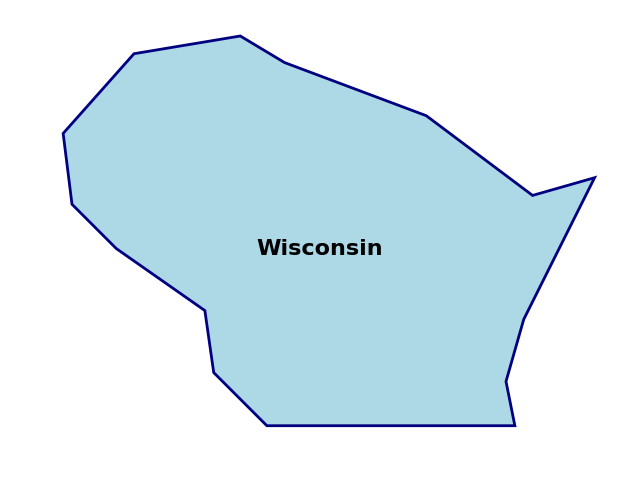

In [12]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# ------------------------------------------------------------
# Rough Wisconsin outline coordinates
# These are simplified points, not GIS-accurate boundaries.
# ------------------------------------------------------------
wisconsin_outline = [
    (-92.1, 46.7),  # NW Corner: Superior / Lake Superior coast
    (-90.9, 46.9),  # North: Bayfield / Apostle Islands
    (-90.4, 46.6),  # North: Montreal River (Start of MI border)
    (-88.8, 46.0),  # NE: Angled land border with Upper MI
    (-87.6, 45.1),  # NE: Marinette / Menominee River mouth
    (-86.9, 45.3),  # East: Tip of the Door County Peninsula
    (-87.7, 43.7),  # East Coast: Lake Michigan near Sheboygan
    (-87.9, 43.0),  # East Coast: Lake Michigan near Milwaukee
    (-87.8, 42.5),  # SE Corner: Kenosha / Illinois border
    (-89.0, 42.5),  # South Border: Straight line across IL border
    (-90.6, 42.5),  # SW Corner: Tri-state point (WI-IL-IA)
    (-91.2, 43.1),  # West Border: Mississippi River (Prairie du Chien)
    (-91.3, 43.8),  # West Border: Mississippi River (La Crosse)
    (-92.3, 44.5),  # West Border: Mississippi River (Lake Pepin)
    (-92.8, 45.0),  # West Border: St. Croix River (Hudson)
    (-92.9, 45.8),  # Westernmost point: St. Croix River bulge
    (-92.1, 46.7)   # Close polygon back to start
]
# Separate longitude and latitude
longitudes = [point[0] for point in wisconsin_outline]
latitudes = [point[1] for point in wisconsin_outline]

# ------------------------------------------------------------
# Create the figure
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))

# Draw Wisconsin polygon
wisconsin = Polygon(
    wisconsin_outline,
    closed=True,
    facecolor="lightblue",
    edgecolor="navy",
    linewidth=2
)

ax.add_patch(wisconsin)

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.set_xlim(-93.5, -86.5)
ax.set_ylim(42.0, 47.2)

ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.5)

# Add label
ax.text(
    -90.0,
    44.5,
    "Wisconsin",
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)

# ------------------------------------------------------------
# Save and show image
# ------------------------------------------------------------
# Add this before plt.savefig in your FIRST script
plt.axis('off')
plt.savefig("wisconsin_map.png", bbox_inches='tight', pad_inches=0)
plt.show()



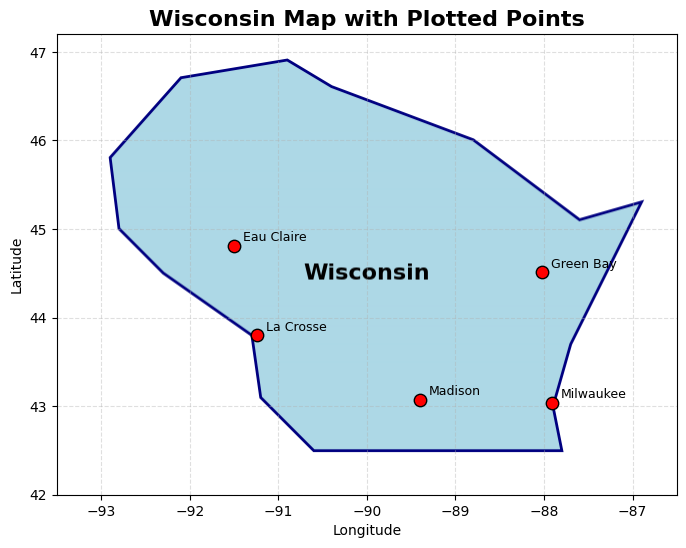

In [13]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# ------------------------------------------------------------
# Load the Wisconsin image you already created
# ------------------------------------------------------------
image_path = Path("wisconsin_map.png")
if not image_path.exists():
    raise FileNotFoundError(f"Map image not found: {image_path.resolve()}")

img = mpimg.imread(str(image_path))

# ------------------------------------------------------------
# Geographic bounds used when the image was created
# These MUST match the axis limits from your first script
# ------------------------------------------------------------
min_lon, max_lon = -93.5, -86.5
min_lat, max_lat = 42.0, 47.2

# ------------------------------------------------------------
# Example points to plot
# Format: (name, longitude, latitude)
# ------------------------------------------------------------
points = [
    ("Madison", -89.4012, 43.0731),
    ("Milwaukee", -87.9065, 43.0389),
    ("Green Bay", -88.0198, 44.5133),
    ("La Crosse", -91.2396, 43.8014),
    ("Eau Claire", -91.4985, 44.8113),
]

# ------------------------------------------------------------
# Create figure and display the image as a map background
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img, extent=[min_lon, max_lon, min_lat, max_lat], aspect="equal")

# ------------------------------------------------------------
# Plot each point
# ------------------------------------------------------------
for name, lon, lat in points:
    ax.scatter(lon, lat, s=80, facecolor="red", edgecolor="black", zorder=3)
    ax.text(lon + 0.1, lat + 0.05, name, fontsize=9, zorder=4)

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------
ax.set_title("Wisconsin Map with Plotted Points", fontsize=16, fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(min_lon, max_lon)
ax.set_ylim(min_lat, max_lat)
ax.grid(True, linestyle="--", alpha=0.4)

# ------------------------------------------------------------
# Save and show
# ------------------------------------------------------------
plt.savefig("wisconsin_map_with_points.png", dpi=300, bbox_inches="tight")
plt.show()


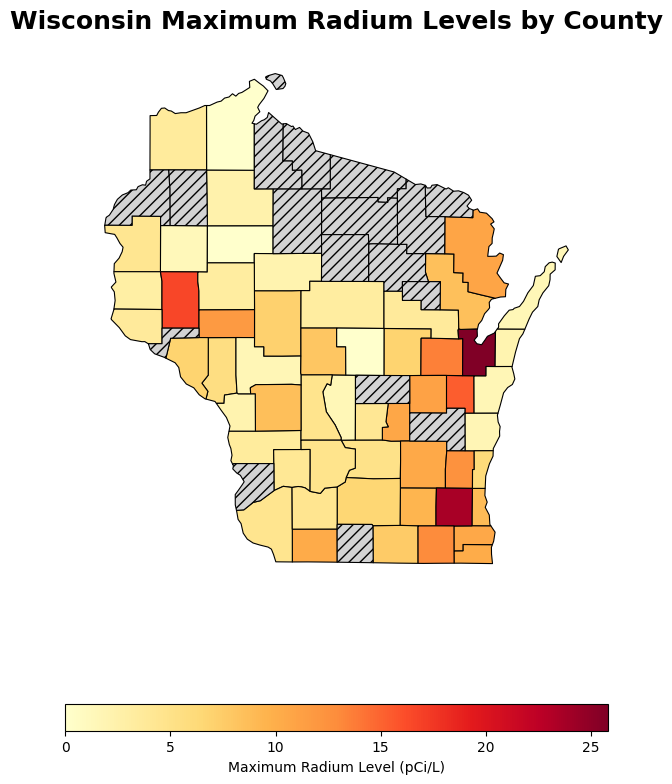

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# ------------------------------------------------------------
# 1. Load Your Radium Data
# ------------------------------------------------------------
data_file = "/Users/ericquezada/Desktop/Projects/Internship 3 UW - Madison/A-Computational-Approach-to-Understanding-the-Temporal-and-Spatial-Extent-of-Combined-Radium-Through/filtered_annual_maximum_radium.xlsx"

try:
    df = pd.read_excel(data_file)
except FileNotFoundError:
    print(f"Error: Could not find {data_file}.")
    exit()

# --- FIXED COLUMN NAMES ---
county_col = "County"
val_col = "Measured Amount"

# Standardize county names (title case, strip whitespace) to ensure they match the map data
df[county_col] = df[county_col].astype(str).str.title().str.strip()

# Safegaurd: Force the 'Measured Amount' column to be numeric. 
# Any weird text (like "ND") gets turned into a blank (NaN) so it doesn't crash the math.
df[val_col] = pd.to_numeric(df[val_col], errors='coerce')

# Aggregate data: Find the maximum radium level per county
county_data = df.groupby(county_col)[val_col].max().reset_index()

# ------------------------------------------------------------
# 2. Fetch Wisconsin County Boundaries
# ------------------------------------------------------------
print("Downloading county boundaries from the US Census Bureau...")
county_shapes_url = "https://www2.census.gov/geo/tiger/GENZ2021/shp/cb_2021_us_county_20m.zip"

us_counties = gpd.read_file(county_shapes_url)
wi_counties = us_counties[us_counties['STATEFP'] == '55'].copy()

# ------------------------------------------------------------
# 3. Merge Data with Geography
# ------------------------------------------------------------
map_data = wi_counties.merge(county_data, left_on='NAME', right_on=county_col, how='left')

# ------------------------------------------------------------
# 4. Create Figure and Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 10))

map_data.plot(
    column=val_col,           
    cmap="YlOrRd",            # Yellow-Orange-Red colormap
    linewidth=0.8,            
    ax=ax,
    edgecolor="black",        
    legend=True,              
    missing_kwds={            
        "color": "lightgrey",
        "hatch": "///",
        "label": "No Data"
    },
    legend_kwds={
        "label": "Maximum Radium Level (pCi/L)", 
        "orientation": "horizontal",
        "shrink": 0.7
    }
)

# ------------------------------------------------------------
# 5. Formatting
# ------------------------------------------------------------
ax.set_title("Wisconsin Maximum Radium Levels by County", fontsize=18, fontweight="bold", pad=15)
ax.axis("off")  

plt.savefig("wisconsin_county_radium_map.png", dpi=300, bbox_inches="tight")
plt.show()

Loading ZIP Code Tabulation Area boundaries...
ZCTA shapes loaded: 208
Matched ZIP codes: 208
ZCTA shapes loaded: 208
Matched ZIP codes: 208


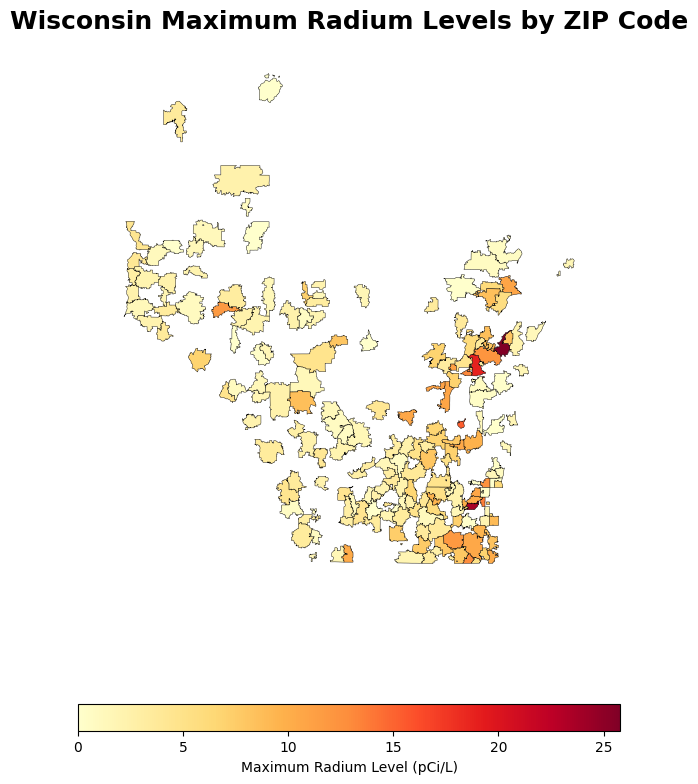

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# ------------------------------------------------------------
# 1. Load Radium Data
# ------------------------------------------------------------
data_file = "filtered_annual_maximum_radium.xlsx"

try:
    df = pd.read_excel(data_file)
except FileNotFoundError:
    print(f"Error: Could not find {data_file}.")
    exit()

zip_col = "Zip"
val_col = "Measured Amount"

# Clean ZIP codes
df[zip_col] = df[zip_col].astype(str).str.replace(".0", "", regex=False)
df[zip_col] = df[zip_col].str.strip().str.zfill(5)

# Clean measured amount
df[val_col] = pd.to_numeric(df[val_col], errors="coerce")

# Remove bad rows
df = df.dropna(subset=[zip_col, val_col])

# Maximum radium level per ZIP
zip_data = df.groupby(zip_col)[val_col].max().reset_index()
needed_zips = set(zip_data[zip_col])

# ------------------------------------------------------------
# 2. Load ZCTA Boundaries Faster with Filtered Cache
# ------------------------------------------------------------
print("Loading ZIP Code Tabulation Area boundaries...")

filtered_cache_file = "zcta_filtered_for_radium.geojson"

if os.path.exists(filtered_cache_file):
    print("Using filtered cached ZCTA file...")
    zctas = gpd.read_file(filtered_cache_file)

else:
    print("Downloading simplified 2020 ZCTA boundaries...")

    zcta_shapes_url = "https://www2.census.gov/geo/tiger/GENZ2020/shp/cb_2020_us_zcta520_500k.zip"

    zctas = gpd.read_file(zcta_shapes_url)

    # Find ZIP column automatically
    possible_zip_cols = ["ZCTA5CE20", "ZCTA5CE10", "GEOID20", "GEOID"]

    zcta_zip_col = None

    for col in possible_zip_cols:
        if col in zctas.columns:
            zcta_zip_col = col
            break

    if zcta_zip_col is None:
        print("Could not find ZIP/ZCTA column.")
        print("Available columns:")
        print(zctas.columns)
        exit()

    zctas[zcta_zip_col] = zctas[zcta_zip_col].astype(str).str.zfill(5)

    # Keep only ZIPs in your radium data
    zctas = zctas[zctas[zcta_zip_col].isin(needed_zips)].copy()

    # Save only the filtered ZIP shapes
    zctas.to_file(filtered_cache_file, driver="GeoJSON")

# ------------------------------------------------------------
# 3. Find ZIP Column Again After Loading Cache
# ------------------------------------------------------------
possible_zip_cols = ["ZCTA5CE20", "ZCTA5CE10", "GEOID20", "GEOID"]

zcta_zip_col = None

for col in possible_zip_cols:
    if col in zctas.columns:
        zcta_zip_col = col
        break

if zcta_zip_col is None:
    print("Could not find ZIP/ZCTA column.")
    print("Available columns:")
    print(zctas.columns)
    exit()

zctas[zcta_zip_col] = zctas[zcta_zip_col].astype(str).str.zfill(5)

print(f"ZCTA shapes loaded: {len(zctas)}")

# ------------------------------------------------------------
# 4. Merge Radium Data with ZIP Boundaries
# ------------------------------------------------------------
map_data = zctas.merge(
    zip_data,
    left_on=zcta_zip_col,
    right_on=zip_col,
    how="inner"
)

print(f"Matched ZIP codes: {len(map_data)}")

if map_data.empty:
    print("No ZIP codes matched. Check your Excel ZIP column.")
    exit()

# ------------------------------------------------------------
# 5. Plot ZIP Code Map
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 10))

map_data.plot(
    column=val_col,
    cmap="YlOrRd",
    linewidth=0.3,
    ax=ax,
    edgecolor="black",
    legend=True,
    legend_kwds={
        "label": "Maximum Radium Level (pCi/L)",
        "orientation": "horizontal",
        "shrink": 0.7
    }
)

ax.set_title("Wisconsin Maximum Radium Levels by ZIP Code", fontsize=18, fontweight="bold", pad=15)
ax.axis("off")

plt.savefig("wisconsin_zipcode_radium_map.png", dpi=300, bbox_inches="tight")
plt.show()

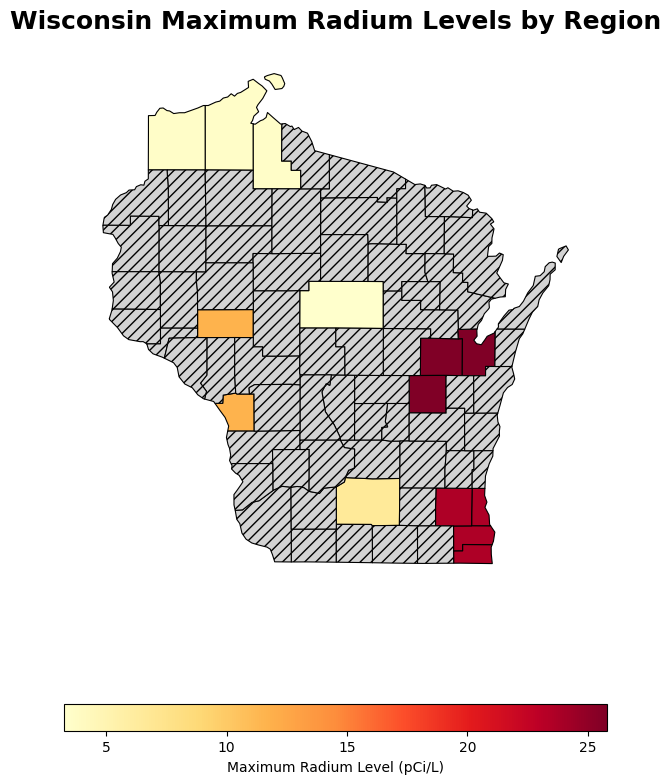

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

data_file = "filtered_annual_maximum_radium.xlsx"

try:
    df = pd.read_excel(data_file)
except FileNotFoundError:
    print(f"Error: Could not find {data_file}.")
    exit()

county_col = "County"
val_col = "Measured Amount"

df[county_col] = df[county_col].astype(str).str.title().str.strip()
df[val_col] = pd.to_numeric(df[val_col], errors="coerce")

region_map = {
    "Dane": "South Central",
    "Milwaukee": "Southeast",
    "Waukesha": "Southeast",
    "Racine": "Southeast",
    "Kenosha": "Southeast",
    "Brown": "Northeast",
    "Outagamie": "Northeast",
    "Winnebago": "Northeast",
    "Marathon": "Central",
    "La Crosse": "Western",
    "Eau Claire": "Western",
    "Douglas": "Northern",
    "Bayfield": "Northern",
    "Ashland": "Northern",
}

df["Region"] = df[county_col].map(region_map)

# Optional: remove rows that were not assigned a region
df = df.dropna(subset=["Region"])

region_data = df.groupby("Region")[val_col].max().reset_index()

# Load county boundaries
county_shapes_url = "https://www2.census.gov/geo/tiger/GENZ2021/shp/cb_2021_us_county_20m.zip"

us_counties = gpd.read_file(county_shapes_url)
wi_counties = us_counties[us_counties["STATEFP"] == "55"].copy()

wi_counties["Region"] = wi_counties["NAME"].map(region_map)

map_data = wi_counties.merge(
    region_data,
    on="Region",
    how="left"
)

fig, ax = plt.subplots(figsize=(10, 10))

map_data.plot(
    column=val_col,
    cmap="YlOrRd",
    linewidth=0.8,
    ax=ax,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "hatch": "///",
        "label": "No Data"
    },
    legend_kwds={
        "label": "Maximum Radium Level (pCi/L)",
        "orientation": "horizontal",
        "shrink": 0.7
    }
)

ax.set_title("Wisconsin Maximum Radium Levels by Region", fontsize=18, fontweight="bold", pad=15)
ax.axis("off")

plt.savefig("wisconsin_region_radium_map.png", dpi=300, bbox_inches="tight")
plt.show()